<a href="https://colab.research.google.com/github/vicayumi/Calculo_Numerico/blob/main/Elimina%C3%A7%C3%A3o_Gauss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Eliminação de Gauss**

Considere o sistema:


$$
\begin{aligned}
2x+y-z&=8,\\
-3x-y+2z&=-11,\\
-2x+y+2z&=-3.
\end{aligned}
$$


Renderizando 154 frames... aguarde.
Concluído!


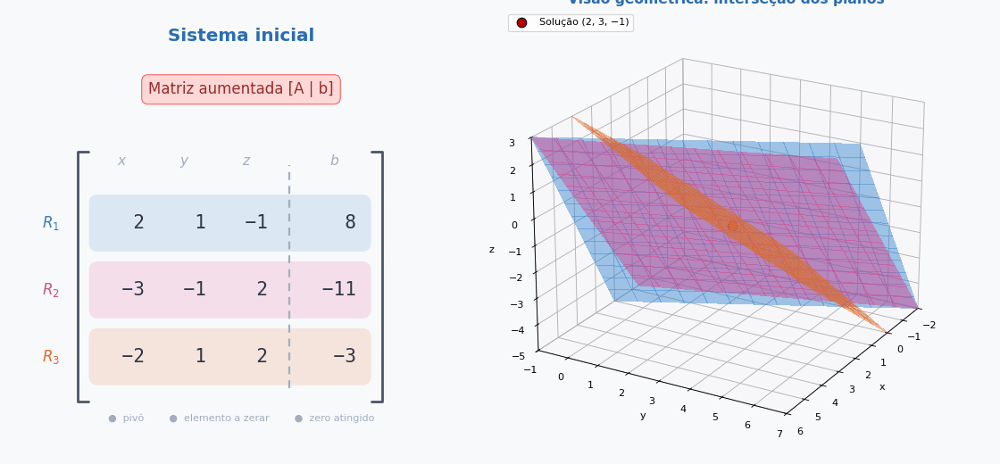

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch
from fractions import Fraction
from IPython.display import Image, display


A = [[ 2,  1, -1,   8],
     [-3, -1,  2, -11],
     [-2,  1,  2,  -3]]

NOMES = ['x', 'y', 'z']
CORES_LINHA = ['#3182ce', '#d53f8c', '#dd6b20']
BG, TXT, CINZA = '#f8f9fa', '#2d3748', '#a0aec0'
LIM = [(-2, 6), (-1, 7), (-5, 3)]
FRAMES_POR_PASSO = 14
ARQUIVO_GIF = 'gauss_e_planos.gif'


def fmt(v):
    """Fraction -> texto bonito (1/2, −3, 0...)."""
    v = Fraction(v)
    s = str(abs(v.numerator)) if v.denominator == 1 else f"{abs(v.numerator)}/{v.denominator}"
    return ("−" if v < 0 else "") + s


def latex_fator(f):
    """Coeficiente da operação entre linhas em LaTeX, sem o sinal."""
    f = abs(Fraction(f))
    if f == 1:
        return ""
    if f.denominator == 1:
        return str(f.numerator)
    return rf"\frac{{{f.numerator}}}{{{f.denominator}}}"


def gerar_passos(A):
    """Executa a eliminação de Gauss e registra cada passo para a animação."""
    n = 3
    M = [[Fraction(x) for x in r] for r in A]
    copia = lambda: [r[:] for r in M]
    passos = [dict(M=copia(), titulo="Sistema inicial", eq="Matriz aumentada [A | b]",
                   pivo=None, alvo=None, fase="init", sol=[None] * n)]

    for k in range(n - 1):
        for i in range(k + 1, n):
            f = -M[i][k] / M[k][k]
            sinal = "+" if f >= 0 else "-"
            eq = rf"$R_{i+1} \leftarrow R_{i+1} {sinal} {latex_fator(f)}\,R_{k+1}$"
            titulo = rf"Zerar $a_{{{i+1}{k+1}}}$"
            passos.append(dict(M=copia(), titulo=titulo, eq=eq, pivo=(k, k),
                               alvo=i, fase="antes", sol=[None] * n))
            M[i] = [M[i][j] + f * M[k][j] for j in range(n + 1)]
            passos.append(dict(M=copia(), titulo=titulo, eq="Zero criado!",
                               pivo=(k, k), alvo=i, fase="depois", sol=[None] * n))

    passos.append(dict(M=copia(), titulo="Fim da eliminação",
                       eq="Matriz triangular superior!", pivo=None, alvo=None,
                       fase="fim", sol=[None] * n))

    sol = [None] * n
    for i in reversed(range(n)):
        s = M[i][n] - sum(M[i][j] * sol[j] for j in range(i + 1, n))
        sol[i] = s / M[i][i]
        passos.append(dict(M=copia(), titulo="Substituição regressiva",
                           eq=f"{NOMES[i]} = {fmt(sol[i])}", pivo=(i, i),
                           alvo=i, fase="back", sol=list(sol)))
    return passos


def superficie(ax, linha, cor):
    """Plano a·x + b·y + c·z = d, recortado na caixa do gráfico."""
    coef = np.array([float(v) for v in linha[:3]])
    d = float(linha[3])
    k = int(np.argmax(np.abs(coef)))          # variável dependente (maior coeficiente)
    i, j = [m for m in range(3) if m != k]
    U, V = np.meshgrid(np.linspace(*LIM[i], 14), np.linspace(*LIM[j], 14))
    W = (d - coef[i] * U - coef[j] * V) / coef[k]
    W = np.where((W >= LIM[k][0]) & (W <= LIM[k][1]), W, np.nan)
    P = [None] * 3
    P[i], P[j], P[k] = U, V, W
    return ax.plot_surface(*P, color=cor, alpha=0.45, linewidth=0,
                           shade=False, antialiased=False)


passos = gerar_passos(A)
solucao = np.linalg.solve(np.array(A, float)[:, :3], np.array(A, float)[:, 3])
TOTAL = len(passos) * FRAMES_POR_PASSO

fig = plt.figure(figsize=(14, 6.5), facecolor=BG)
gs = GridSpec(1, 2, width_ratios=[1, 1.15], wspace=0.02, left=0.02, right=0.98,
              top=0.98, bottom=0.02)
axL = fig.add_subplot(gs[0])
axR = fig.add_subplot(gs[1], projection='3d')
axL.set_xlim(0, 1); axL.set_ylim(0, 1); axL.axis('off')
axL.set_facecolor(BG)

txt_titulo = axL.text(0.5, 0.94, '', fontsize=18, ha='center', va='center',
                      fontweight='bold', color='#2b6cb0')
txt_eq = axL.text(0.5, 0.82, '', fontsize=15, ha='center', va='center', color='#9b2c2c',
                  bbox=dict(facecolor='#fed7d7', edgecolor='#f56565',
                            boxstyle='round,pad=0.45'))

XS = [0.23, 0.37, 0.51, 0.71]
YS = [0.52, 0.37, 0.22]
for x, nome in zip(XS[:3], NOMES):
    axL.text(x, 0.65, nome, fontsize=14, ha='center', color=CINZA, style='italic')
axL.text(XS[3], 0.65, 'b', fontsize=14, ha='center', color=CINZA, style='italic')

for xb, dx in [(0.13, 0.025), (0.82, -0.025)]:
    axL.plot([xb + dx, xb, xb, xb + dx], [0.68, 0.68, 0.12, 0.12], color='#4a5568', lw=2.5,
             solid_capstyle='round')
axL.plot([0.61, 0.61], [0.15, 0.65], color=CINZA, lw=2, linestyle=(0, (4, 3)))

faixas = []
for i, y in enumerate(YS):
    p = FancyBboxPatch((0.16, y - 0.06), 0.63, 0.12,
                       boxstyle="round,pad=0.004,rounding_size=0.02",
                       facecolor=CORES_LINHA[i], edgecolor=CORES_LINHA[i], alpha=0.12, lw=0)
    axL.add_patch(p)
    faixas.append(p)
    axL.text(0.07, y, f"$R_{i+1}$", fontsize=15, ha='center', va='center',
             color=CORES_LINHA[i], fontweight='bold')

caixa_pivo = FancyBboxPatch((0, 0), 0.1, 0.1, boxstyle="round,pad=0.003,rounding_size=0.015",
                            facecolor='none', edgecolor='#3182ce', lw=2.5, visible=False)
axL.add_patch(caixa_pivo)

celulas = [[axL.text(XS[j], YS[i], '', fontsize=19, ha='center', va='center',
                     family='monospace') for j in range(4)] for i in range(3)]

axL.text(0.5, 0.075, "●  pivô        ●  elemento a zerar        ●  zero atingido",
         fontsize=10, ha='center', color=CINZA)
txt_sol = axL.text(0.5, 0.02, '', fontsize=14, ha='center', va='center',
                   family='monospace', color='#276749', fontweight='bold')

axR.set_facecolor(BG)
axR.set_xlim(*LIM[0]); axR.set_ylim(*LIM[1]); axR.set_zlim(*LIM[2])
axR.set_box_aspect((1, 1, 0.8))
for eixo in (axR.xaxis, axR.yaxis, axR.zaxis):
    eixo.set_pane_color((0.97, 0.97, 0.98, 1))
axR.set_xlabel('x'); axR.set_ylabel('y'); axR.set_zlabel('z')
axR.set_title('Visão geométrica: interseção dos planos',
              fontweight='bold', color='#2b6cb0', fontsize=14)
axR.scatter(*solucao, color='red', s=90, edgecolor='black', zorder=10,
            label=f'Solução ({", ".join(fmt(round(v, 6)) for v in solucao)})')
axR.legend(loc='upper left')

estado = {'passo': None, 'superficies': []}


def atualizar(g):
    idx = g // FRAMES_POR_PASSO
    st = passos[idx]
    M, pivo, alvo, fase = st['M'], st['pivo'], st['alvo'], st['fase']

    txt_titulo.set_text(st['titulo'])
    txt_eq.set_text(st['eq'])
    txt_eq.set_visible(bool(st['eq']))

    for i in range(3):
        ativa = (alvo == i)
        faixas[i].set_alpha(0.32 if ativa else (0.14 if alvo is None else 0.07))
        faixas[i].set_linewidth(2.5 if ativa else 0)
        for j in range(4):
            t = celulas[i][j]
            t.set_text(f"{fmt(M[i][j]):>4}")
            t.set_color(TXT); t.set_fontweight('normal')
            if pivo == (i, j):
                t.set_color('#3182ce'); t.set_fontweight('bold')
            elif fase in ('antes', 'depois') and i == alvo and j == pivo[1]:
                t.set_color('#e53e3e' if M[i][j] != 0 else '#38a169')
                t.set_fontweight('bold')

    if pivo:
        caixa_pivo.set_visible(True)
        caixa_pivo.set_bounds(XS[pivo[1]] - 0.055, YS[pivo[0]] - 0.05, 0.11, 0.10)
    else:
        caixa_pivo.set_visible(False)

    partes = [f"{n} = {fmt(v) if v is not None else '?'}" for n, v in zip(NOMES, st['sol'])]
    txt_sol.set_text("   ".join(partes) if fase == 'back' else '')

    if estado['passo'] != idx:
        for s in estado['superficies']:
            s.remove()
        estado['superficies'] = [superficie(axR, M[i], CORES_LINHA[i]) for i in range(3)]
        estado['passo'] = idx

    axR.view_init(elev=22, azim=30 + 360 * g / TOTAL)


ani = animation.FuncAnimation(fig, atualizar, frames=TOTAL, interval=140)

print(f"Renderizando {TOTAL} frames... aguarde.")
ani.save(ARQUIVO_GIF, writer='pillow', fps=7, dpi=80)
plt.close(fig)

print("Concluído!")
display(Image(filename=ARQUIVO_GIF))